In [295]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
import joblib
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import warnings
warnings.filterwarnings("ignore")

np.random.seed(42)

# Set style for better plots
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

print("Libraries imported successfful!")

Libraries imported successfful!


In [296]:
print("Loading the dataset.....")
train_df = pd.read_csv("train.csv")

print(f"Dataset shape: {train_df.shape}")
print("\nFirst 5 rows:")
train_df.head()

Loading the dataset.....
Dataset shape: (18524, 9)

First 5 rows:


,id,Time_spent_Alone,Stage_fear,Social_event_attendance,Going_outside,Drained_after_socializing,Friends_circle_size,Post_frequency,Personality
0,0,0.0,No,6.0,4.0,No,15.0,5.0,Extrovert
1,1,1.0,No,7.0,3.0,No,10.0,8.0,Extrovert
2,2,6.0,Yes,1.0,0.0,NaN,3.0,0.0,Introvert
3,3,3.0,No,7.0,3.0,No,11.0,5.0,Extrovert
4,4,1.0,No,4.0,4.0,No,13.0,NaN,Extrovert


In [297]:
test_df = pd.read_csv("test.csv")
print(f" Test Dataset shape: {test_df.shape}")
print("\n First 5 rows:")
test_df.head()

 Test Dataset shape: (6175, 8)

 First 5 rows:


,id,Time_spent_Alone,Stage_fear,Social_event_attendance,Going_outside,Drained_after_socializing,Friends_circle_size,Post_frequency
0,18524,3.0,No,7.0,4.0,No,6.0,NaN
1,18525,NaN,Yes,0.0,0.0,Yes,5.0,1.0
2,18526,3.0,No,5.0,6.0,No,15.0,9.0
3,18527,3.0,No,4.0,4.0,No,5.0,6.0
4,18528,9.0,Yes,1.0,2.0,Yes,1.0,1.0


In [298]:
list(test_df.columns)

['id',
 'Time_spent_Alone',
 'Stage_fear',
 'Social_event_attendance',
 'Going_outside',
 'Drained_after_socializing',
 'Friends_circle_size',
 'Post_frequency']

In [299]:
list(train_df.columns)

['id',
 'Time_spent_Alone',
 'Stage_fear',
 'Social_event_attendance',
 'Going_outside',
 'Drained_after_socializing',
 'Friends_circle_size',
 'Post_frequency',
 'Personality']

In [300]:
#Explore the Dataset
print(" Exploring the dataset..... ")

print(f" Data Info:")
print(f"Shape: {train_df.shape}")
print(f"Columns: {list(train_df.columns)}")

print(f"\n Data Types:")
print(train_df.dtypes)

print(f"\n Missing Values:")
print(train_df.isnull().sum())

print(f"\n Personality Distribution:")
print(train_df['Personality'].value_counts())

print(f"\n Basic Statistics:")
train_df.describe()

 Exploring the dataset..... 
 Data Info:
Shape: (18524, 9)
Columns: ['id', 'Time_spent_Alone', 'Stage_fear', 'Social_event_attendance', 'Going_outside', 'Drained_after_socializing', 'Friends_circle_size', 'Post_frequency', 'Personality']

 Data Types:
id                             int64
Time_spent_Alone             float64
Stage_fear                    object
Social_event_attendance      float64
Going_outside                float64
Drained_after_socializing     object
Friends_circle_size          float64
Post_frequency               float64
Personality                   object
dtype: object

 Missing Values:
id                              0
Time_spent_Alone             1190
Stage_fear                   1893
Social_event_attendance      1180
Going_outside                1466
Drained_after_socializing    1149
Friends_circle_size          1054
Post_frequency               1264
Personality                     0
dtype: int64

 Personality Distribution:
Personality
Extrovert    13699
Intro

,id,Time_spent_Alone,Social_event_attendance,Going_outside,Friends_circle_size,Post_frequency
count,18524.000000,17334.000000,17344.000000,17058.000000,17470.000000,17260.000000
mean,9261.500000,3.137764,5.265106,4.044319,7.996737,4.982097
std,5347.562529,3.003786,2.753359,2.062580,4.223484,2.879139
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4630.750000,1.000000,3.000000,3.000000,5.000000,3.000000
50%,9261.500000,2.000000,5.000000,4.000000,8.000000,5.000000
75%,13892.250000,4.000000,8.000000,6.000000,12.000000,7.000000
max,18523.000000,11.000000,10.000000,7.000000,15.000000,10.000000


In [301]:

#Explore the Dataset
print(" Exploring the Test dataset..... ")

print(f" Data Info:")
print(f"Shape: {test_df.shape}")
print(f"Columns: {list(test_df.columns)}")

print(f"\n Data Types:")
print(test_df.dtypes)

print(f"\n Missing Values:")
print(test_df.isnull().sum())
print(f"\n Basic Statistics:")
print(test_df.describe())

 Exploring the Test dataset..... 
 Data Info:
Shape: (6175, 8)
Columns: ['id', 'Time_spent_Alone', 'Stage_fear', 'Social_event_attendance', 'Going_outside', 'Drained_after_socializing', 'Friends_circle_size', 'Post_frequency']

 Data Types:
id                             int64
Time_spent_Alone             float64
Stage_fear                    object
Social_event_attendance      float64
Going_outside                float64
Drained_after_socializing     object
Friends_circle_size          float64
Post_frequency               float64
dtype: object

 Missing Values:
id                             0
Time_spent_Alone             425
Stage_fear                   598
Social_event_attendance      397
Going_outside                466
Drained_after_socializing    432
Friends_circle_size          350
Post_frequency               408
dtype: int64

 Basic Statistics:
                 id  Time_spent_Alone  Social_event_attendance  Going_outside  \
count   6175.000000       5750.000000              57

In [302]:
train_df["Personality"].value_counts(dropna=False)


Personality
Extrovert    13699
Introvert     4825
Name: count, dtype: int64

In [303]:
le = LabelEncoder()
train_df["Personality"] = le.fit_transform(train_df["Personality"])


In [304]:
columns_to_convert = [
    'Stage_fear',
    'Drained_after_socializing',
    
]

train_df[columns_to_convert] = train_df[columns_to_convert].apply(
    lambda col: pd.to_numeric(col, errors='coerce').fillna(0).astype(int)
)


In [305]:
print(train_df.dtypes)

id                             int64
Time_spent_Alone             float64
Stage_fear                     int64
Social_event_attendance      float64
Going_outside                float64
Drained_after_socializing      int64
Friends_circle_size          float64
Post_frequency               float64
Personality                    int64
dtype: object


In [306]:
columns_to_convert = [
    'Stage_fear',
    'Drained_after_socializing'
]
test_df[columns_to_convert] = test_df[columns_to_convert].apply(
    lambda col: pd.to_numeric(col, errors='coerce').fillna(0).astype(int)
)

In [307]:
print(test_df.dtypes)

id                             int64
Time_spent_Alone             float64
Stage_fear                     int64
Social_event_attendance      float64
Going_outside                float64
Drained_after_socializing      int64
Friends_circle_size          float64
Post_frequency               float64
dtype: object


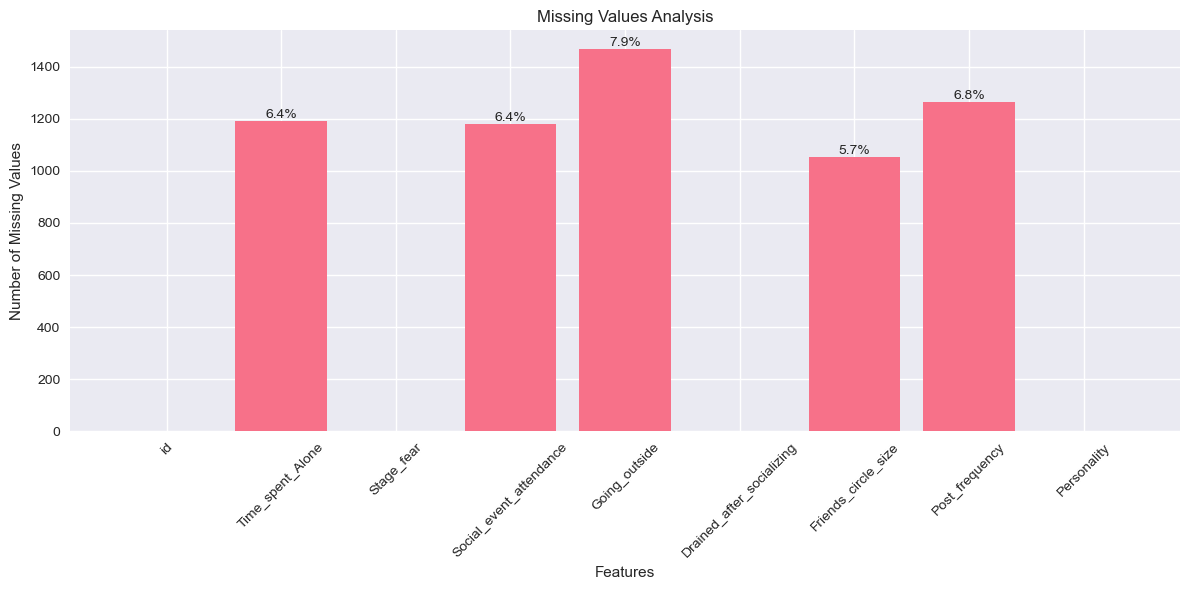

Missing values summary:
                         Missing Count  Missing Percentage
Time_spent_Alone                  1190            6.424098
Social_event_attendance           1180            6.370114
Going_outside                     1466            7.914057
Friends_circle_size               1054            5.689916
Post_frequency                    1264            6.823580


In [308]:
# Missing values analysis
missing_data = train_df.isnull().sum()
missing_percent = (missing_data / len(train_df)) * 100

plt.figure(figsize=(12, 6))
bars = plt.bar(range(len(missing_data)), missing_data.values)
plt.title('Missing Values Analysis')
plt.xlabel('Features')
plt.ylabel('Number of Missing Values')
plt.xticks(range(len(missing_data)), missing_data.index, rotation=45)

# Add percentage labels on bars
for i, (bar, percent) in enumerate(zip(bars, missing_percent.values)):
    if percent > 0:
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1, 
                f'{percent:.1f}%', ha='center', va='bottom')

plt.tight_layout()
plt.show()

print("Missing values summary:")
missing_summary = pd.DataFrame({
    'Missing Count': missing_data,
    'Missing Percentage': missing_percent
})
print(missing_summary[missing_summary['Missing Count'] > 0])

In [309]:
# Check for missing values
print("Missing values check:")
print(f"Total missing values: {train_df.isnull().sum().sum()}")
print(f"Missing values per column:")
print(train_df.isnull().sum())

# No missing values, so no cleaning needed
train_df_clean = train_df.copy()
print(f"\nDataset is clean! Shape: {train_df_clean.shape}")

Missing values check:
Total missing values: 6154
Missing values per column:
id                              0
Time_spent_Alone             1190
Stage_fear                      0
Social_event_attendance      1180
Going_outside                1466
Drained_after_socializing       0
Friends_circle_size          1054
Post_frequency               1264
Personality                     0
dtype: int64

Dataset is clean! Shape: (18524, 9)


In [310]:
train_df_clean.isna().sum()


id                              0
Time_spent_Alone             1190
Stage_fear                      0
Social_event_attendance      1180
Going_outside                1466
Drained_after_socializing       0
Friends_circle_size          1054
Post_frequency               1264
Personality                     0
dtype: int64

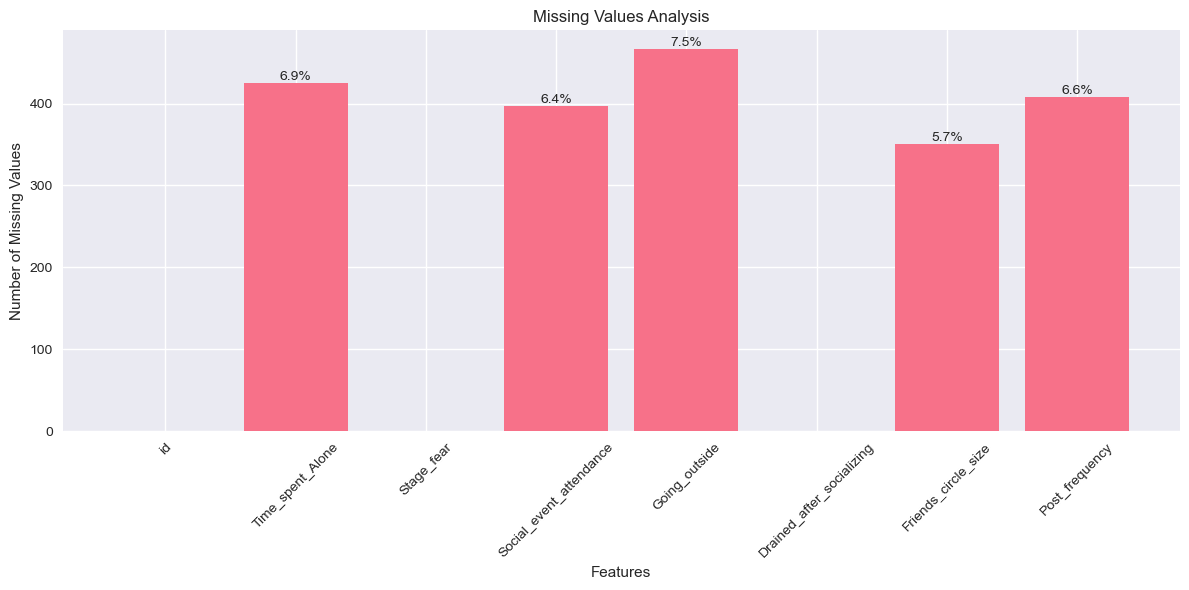

Missing values summary:
                         Missing Count  Missing Percentage
Time_spent_Alone                   425            6.882591
Social_event_attendance            397            6.429150
Going_outside                      466            7.546559
Friends_circle_size                350            5.668016
Post_frequency                     408            6.607287


In [311]:
# Missing values analysis
missing_data = test_df.isnull().sum()
missing_percent = (missing_data / len(test_df)) * 100

plt.figure(figsize=(12, 6))
bars = plt.bar(range(len(missing_data)), missing_data.values)
plt.title('Missing Values Analysis')
plt.xlabel('Features')
plt.ylabel('Number of Missing Values')
plt.xticks(range(len(missing_data)), missing_data.index, rotation=45)

# Add percentage labels on bars
for i, (bar, percent) in enumerate(zip(bars, missing_percent.values)):
    if percent > 0:
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1, 
                f'{percent:.1f}%', ha='center', va='bottom')

plt.tight_layout()
plt.show()

print("Missing values summary:")
missing_summary = pd.DataFrame({
    'Missing Count': missing_data,
    'Missing Percentage': missing_percent
})
print(missing_summary[missing_summary['Missing Count'] > 0])

In [312]:
# Handle missing values
print("Before cleaning:")
print(f"Shape: {test_df.shape}")
print(f"Missing values: {test_df.isnull().sum().sum()}")

# Drop rows with missing values (only a few rows)
test_df_clean = test_df.dropna()

print("\nAfter cleaning:")
print(f"Shape: {test_df_clean.shape}")
print(f"Missing values: {test_df_clean.isnull().sum().sum()}")


Before cleaning:
Shape: (6175, 8)
Missing values: 2046

After cleaning:
Shape: (4277, 8)
Missing values: 0


In [313]:
test_df_clean.head()

,id,Time_spent_Alone,Stage_fear,Social_event_attendance,Going_outside,Drained_after_socializing,Friends_circle_size,Post_frequency
2,18526,3.0,0,5.0,6.0,0,15.0,9.0
3,18527,3.0,0,4.0,4.0,0,5.0,6.0
4,18528,9.0,0,1.0,2.0,0,1.0,1.0
5,18529,2.0,0,5.0,3.0,0,10.0,4.0
6,18530,3.0,0,4.0,5.0,0,15.0,5.0


In [314]:
#prepare data for machine learning
print("Preparing data for machine learning")
#target is already in binary 

#select relevant features
feature_columns= [
 'id', 'Time_spent_Alone', 'Stage_fear', 'Social_event_attendance', 'Going_outside',
'Drained_after_socializing', 'Friends_circle_size', 'Post_frequency']

X = train_df_clean[feature_columns].copy()
y = train_df_clean['Personality'].copy()

#convert categorical colunms into multiple binary (0/1) columns
X = pd.get_dummies(X, drop_first = True)

print("After encoding:")
X.head()
print(f" Data Preparation:")
print(f"Features (X): {X.shape}")
print(f"Target (y): {y.shape}")
print(f"Feature names: {list(X.columns)}")

print(f"\n Personality Distribution:")
print(f" Extrovert (0): {sum(y == 0)} samples ({sum(y == 0)/len(y)*100:.1f}%)")
print(f"Introvert (1): {sum(y == 1)} samples ({sum(y == 1)/len(y)*100:.1f}%)")

print("\n Data is ready for machine learning!")

Preparing data for machine learning
After encoding:
 Data Preparation:
Features (X): (18524, 8)
Target (y): (18524,)
Feature names: ['id', 'Time_spent_Alone', 'Stage_fear', 'Social_event_attendance', 'Going_outside', 'Drained_after_socializing', 'Friends_circle_size', 'Post_frequency']

 Personality Distribution:
 Extrovert (0): 13699 samples (74.0%)
Introvert (1): 4825 samples (26.0%)

 Data is ready for machine learning!


In [315]:
# Prepare test data for machine learning
print("Preparing test data for machine learning")
print("*" * 45)

# Keep the ID column for submission later
test_ids = test_df_clean['id']

# Select the same relevant features used during training
feature_columns = [
    'Time_spent_Alone', 'Stage_fear', 'Social_event_attendance', 'Going_outside', 
     'Drained_after_socializing', 'Friends_circle_size', 'Post_frequency']
    
# Copy only the relevant columns
test_df_clean = test_df_clean[feature_columns].copy()

# Convert categorical columns into multiple binary (0/1) columns
test_df_clean = pd.get_dummies(test_df_clean, drop_first=True)

# Align test columns with training columns
# (Make sure you have X_train already prepared from your training code)
test_df_clean = test_df_clean.reindex(columns=X_train.columns, fill_value=0)

print("After encoding:")
print(test_df_clean.head())

print(f"\nData Preparation:")
print(f"Features (test_df): {test_df_clean.shape}")
print(f"Feature names: {list(test_df_clean.columns)}")

print("\n Test data is ready for machine learning!")


Preparing test data for machine learning
*********************************************
After encoding:
   Time_spent_Alone  Stage_fear  Social_event_attendance  Going_outside  \
2               3.0           0                      5.0            6.0   
3               3.0           0                      4.0            4.0   
4               9.0           0                      1.0            2.0   
5               2.0           0                      5.0            3.0   
6               3.0           0                      4.0            5.0   

   Drained_after_socializing  Friends_circle_size  Post_frequency  
2                          0                 15.0             9.0  
3                          0                  5.0             6.0  
4                          0                  1.0             1.0  
5                          0                 10.0             4.0  
6                          0                 15.0             5.0  

Data Preparation:
Features (test_df):

In [316]:
test_df_clean.head()

,Time_spent_Alone,Stage_fear,Social_event_attendance,Going_outside,Drained_after_socializing,Friends_circle_size,Post_frequency
2,3.0,0,5.0,6.0,0,15.0,9.0
3,3.0,0,4.0,4.0,0,5.0,6.0
4,9.0,0,1.0,2.0,0,1.0,1.0
5,2.0,0,5.0,3.0,0,10.0,4.0
6,3.0,0,4.0,5.0,0,15.0,5.0


In [317]:
# Split data and scale Features
print ("Spliting data and scalaing features")
print("*" * 45)
# Split data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f" Data Split:")
print(f"Training set: {x_train.shape[0]} samples")
print(f"Test set: {x_test.shape[0]} samples")

# Scale the features
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

print("\n Data split and scaled!")

Spliting data and scalaing features
*********************************************
 Data Split:
Training set: 14819 samples
Test set: 3705 samples

 Data split and scaled!


In [318]:
# Prepare test data for machine learning
print("Preparing test data for machine learning")
print("*" * 45)

# Keep a copy of the ID column for later submission
test_ids = test_df['id']

# Select the same relevant features used during training
feature_columns = [
   'Time_spent_Alone', 'Stage_fear', 'Social_event_attendance', 'Going_outside', 
     'Drained_after_socializing', 'Friends_circle_size', 'Post_frequency']
    

# Copy the relevant columns for model input
test_features = test_df_clean[feature_columns].copy()

# Convert categorical columns into multiple binary (0/1) columns
test_features = pd.get_dummies(test_features, drop_first=True)

# Align test columns with training columns (same structure as X_train)
test_features = test_features.reindex(columns=X_train.columns, fill_value=0)

print("After encoding:")
print(test_features.head())

print(f"\nData Preparation:")
print(f"Feature data (test_features): {test_features.shape}")
print(f"Feature names: {list(test_features.columns)}")

print("\n Test data is ready for machine learning!")




Preparing test data for machine learning
*********************************************
After encoding:
   Time_spent_Alone  Stage_fear  Social_event_attendance  Going_outside  \
2               3.0           0                      5.0            6.0   
3               3.0           0                      4.0            4.0   
4               9.0           0                      1.0            2.0   
5               2.0           0                      5.0            3.0   
6               3.0           0                      4.0            5.0   

   Drained_after_socializing  Friends_circle_size  Post_frequency  
2                          0                 15.0             9.0  
3                          0                  5.0             6.0  
4                          0                  1.0             1.0  
5                          0                 10.0             4.0  
6                          0                 15.0             5.0  

Data Preparation:
Feature data (test_

In [319]:
# Prepare features and target
# Remove features that are not useful for prediction
# Correct list of columns to REMOVE
remove_cols = [ 'id', 'Personality']

# Keep only useful features
feature_columns = [col for col in train_df_clean.columns if col not in remove_cols]

#Define target correctly
y = train_df_clean['Personality']

#fill any missing values in target(rare)
y = y.fillna(y.mode()[0])   # fill NaN with most common value

#define X after feature list is created
X = train_df_clean[feature_columns]
y = train_df_clean['Personality']

print("Feature columns:")
print(X.columns.tolist())
print(f"\nFeature matrix shape: {X.shape}")
print(f"Target shape: {y.shape}")
print(f"\nTarget statistics:")
print(f"Mean: {y.mean():.2f}")
print(f"Std: {y.std():.2f}")
print(f"Min: {y.min()}")
print(f"Max: {y.max()}")

Feature columns:
['Time_spent_Alone', 'Stage_fear', 'Social_event_attendance', 'Going_outside', 'Drained_after_socializing', 'Friends_circle_size', 'Post_frequency']

Feature matrix shape: (18524, 7)
Target shape: (18524,)

Target statistics:
Mean: 0.26
Std: 0.44
Min: 0
Max: 1


In [320]:
train_df_clean.isna().sum()


id                              0
Time_spent_Alone             1190
Stage_fear                      0
Social_event_attendance      1180
Going_outside                1466
Drained_after_socializing       0
Friends_circle_size          1054
Post_frequency               1264
Personality                     0
dtype: int64

In [321]:


# Replace hidden NaN-like strings
train_df_clean = train_df_clean.replace(["?", " ", "", "None", "NA", "NaN", "nan", "--"], np.nan)

# Convert numeric-looking object columns to numeric
for col in train_df_clean.columns:
    train_df_clean[col] = pd.to_numeric(train_df_clean[col], errors="ignore")

# Fill missing values for every column
for col in train_df_clean.columns:
    if train_df_clean[col].dtype in ["int64", "float64"]:
        # numeric column
        train_df_clean[col] = train_df_clean[col].fillna(train_df_clean[col].median())
    else:
        try:
            train_df_clean[col] = train_df_clean[col].fillna(train_df_clean[col].mode()[0])
        except:
            # If mode fails (all NaN), fill with "Unknown"
            train_df_clean[col] = train_df_clean[col].fillna("Unknown")


In [322]:
train_df_clean.isna().sum()


id                           0
Time_spent_Alone             0
Stage_fear                   0
Social_event_attendance      0
Going_outside                0
Drained_after_socializing    0
Friends_circle_size          0
Post_frequency               0
Personality                  0
dtype: int64

In [323]:
remove_cols = ["id", "Personality"]
X = train_df_clean.drop(columns=remove_cols, errors="ignore")
y = train_df_clean["Personality"]


In [324]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.25, random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X_train, y_train, test_size=0.20, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)


In [325]:
# Train/Validation/Test split
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")
print(f"\nTraining target statistics:")
print(f"Mean: {y_train.mean():.2f}")
print(f"Std: {y_train.std():.2f}")

Training set: 11114 samples
Validation set: 3705 samples
Test set: 3705 samples

Training target statistics:
Mean: 0.26
Std: 0.44


In [326]:
# Create preprocessing pipeline

# All features are numerical, so we only need scaling
preprocessor = StandardScaler()

# Fit on training data
X_train_scaled = preprocessor.fit_transform(X_train)
X_val_scaled = preprocessor.transform(X_val)
X_test_scaled = preprocessor.transform(X_test)

print("Preprocessing completed:")
print(f"Training set scaled shape: {X_train_scaled.shape}")
print(f"Validation set scaled shape: {X_val_scaled.shape}")
print(f"Test set scaled shape: {X_test_scaled.shape}")

Preprocessing completed:
Training set scaled shape: (11114, 7)
Validation set scaled shape: (3705, 7)
Test set scaled shape: (3705, 7)


In [327]:
# Train Logistic Regression model
model = LogisticRegression(random_state=42, max_iter=1000)
model.fit(X_train_scaled, y_train)

# Make predictions
y_train_pred = model.predict(X_train_scaled)
y_val_pred = model.predict(X_val_scaled)
y_test_pred = model.predict(X_test_scaled)

# Get prediction probabilities
y_train_proba = model.predict_proba(X_train_scaled)[:, 1]
y_val_proba = model.predict_proba(X_val_scaled)[:, 1]
y_test_proba = model.predict_proba(X_test_scaled)[:, 1]

print("Model training completed!")
print(f"Training accuracy: {model.score(X_train_scaled, y_train):.4f}")
print(f"Validation accuracy: {model.score(X_val_scaled, y_val):.4f}")
print(f"Test accuracy: {model.score(X_test_scaled, y_test):.4f}")

Model training completed!
Training accuracy: 0.9672
Validation accuracy: 0.9663
Test accuracy: 0.9671


In [328]:
print("NaN count per column:")
print(train_df_clean.isna().sum())


NaN count per column:
id                           0
Time_spent_Alone             0
Stage_fear                   0
Social_event_attendance      0
Going_outside                0
Drained_after_socializing    0
Friends_circle_size          0
Post_frequency               0
Personality                  0
dtype: int64


In [329]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# 1. Impute missing values
imputer = SimpleImputer(strategy='median')
x_imputed = imputer.fit_transform(X)

# 2. Scale data
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x_imputed)

# 3. Split your data
x_train_scaled, x_test_scaled, y_train, y_test = train_test_split(
    x_scaled, y, test_size=0.2, random_state=42
)


In [330]:
imputer = SimpleImputer(strategy='most_frequent')


In [331]:
# Train model
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(x_train_scaled, y_train)

# Predictions
lr_train_pred = lr_model.predict(x_train_scaled)
lr_test_pred = lr_model.predict(x_test_scaled)

# Metrics
lr_train_acc = accuracy_score(y_train, lr_train_pred)
lr_test_acc = accuracy_score(y_test, lr_test_pred)
lr_test_precision = precision_score(y_test, lr_test_pred, average='binary')
lr_test_recall = recall_score(y_test, lr_test_pred, average='binary')
lr_test_f1 = f1_score(y_test, lr_test_pred, average='binary')

print(f" Logistic Regression Results:")
print(f"   Train Accuracy: {lr_train_acc:.4f}")
print(f"   Test Accuracy: {lr_test_acc:.4f}")
print(f"   Test Precision: {lr_test_precision:.4f}")
print(f"   Test Recall: {lr_test_recall:.4f}")
print(f"   Test F1-Score: {lr_test_f1:.4f}")

print("\n What this means:")
print(f"- Accuracy of {lr_test_acc:.3f} means {lr_test_acc*100:.1f}% correct predictions")
print(f"- Precision of {lr_test_precision:.3f} means {lr_test_precision*100:.1f}% of subscription predictions are correct")
print(f"- Recall of {lr_test_recall:.3f} means {lr_test_recall*100:.1f}% of actual subscribers are caught")
print(f"- F1-Score of {lr_test_f1:.3f} balances precision and recall")


 Logistic Regression Results:
   Train Accuracy: 0.9672
   Test Accuracy: 0.9665
   Test Precision: 0.9442
   Test Recall: 0.9244
   Test F1-Score: 0.9342

 What this means:
- Accuracy of 0.967 means 96.7% correct predictions
- Precision of 0.944 means 94.4% of subscription predictions are correct
- Recall of 0.924 means 92.4% of actual subscribers are caught
- F1-Score of 0.934 balances precision and recall


In [332]:
print("Accuracy:")
print(f" • Value: {lr_test_acc:.3f} ({lr_test_acc*100:.1f}%)")
print("   • Meaning: Percentage of correct predictions")
print("   • Formula: (True Positives + True Negatives) / Total")
print("   • Business Impact: Overall model correctness")
print("   • Good for: Balanced datasets")
print()

print(" Precision:")
print(f"   • Value: {lr_test_precision:.3f} ({lr_test_precision*100:.1f}%)")
print("   • Meaning: Of all customers predicted to subscribe, how many actually subscribed?")
print("   • Formula: True Positives / (True Positives + False Positives)")
print("   • Business Impact: Reduces false alarms, saves marketing costs")
print("   • Good for: When false positives are expensive")
print()

print(" Recall (Sensitivity):")
print(f"   • Value: {lr_test_recall:.3f} ({lr_test_recall*100:.1f}%)")
print("   • Meaning: Of all customers who actually churn, how many did we catch?")
print("   • Formula: True Positives / (True Positives + False Negatives)")
print("   • Business Impact: Captures more churning customers")
print("   • Good for: When missing subscribers is expensive")
print()

print(" F1-Score:")
print(f"   • Value: {lr_test_f1:.3f}")
print("   • Meaning: Harmonic mean of precision and recall")
print("   • Formula: 2 × (Precision × Recall) / (Precision + Recall)")
print("   • Business Impact: Balanced measure when both precision and recall matter")
print("   • Good for: Imbalanced datasets")
print()

print(" Confusion Matrix:")
cm = confusion_matrix(y_test, lr_test_pred)
print(f"   • True Negatives (Extrovert predicted as Extrovert): {cm[0,0]}")
print(f"   • False Positives (Extrovert predicted as Introvert): {cm[0,1]}")
print(f"   • False Negatives (Introvert predicted as Extrovert): {cm[1,0]}")
print(f"   • True Positives (Introvert predicted as Introvert): {cm[1,1]}")
print("   • Business Impact: Shows exactly where model makes mistakes")


Accuracy:
 • Value: 0.967 (96.7%)
   • Meaning: Percentage of correct predictions
   • Formula: (True Positives + True Negatives) / Total
   • Business Impact: Overall model correctness
   • Good for: Balanced datasets

 Precision:
   • Value: 0.944 (94.4%)
   • Meaning: Of all customers predicted to subscribe, how many actually subscribed?
   • Formula: True Positives / (True Positives + False Positives)
   • Business Impact: Reduces false alarms, saves marketing costs
   • Good for: When false positives are expensive

 Recall (Sensitivity):
   • Value: 0.924 (92.4%)
   • Meaning: Of all customers who actually churn, how many did we catch?
   • Formula: True Positives / (True Positives + False Negatives)
   • Business Impact: Captures more churning customers
   • Good for: When missing subscribers is expensive

 F1-Score:
   • Value: 0.934
   • Meaning: Harmonic mean of precision and recall
   • Formula: 2 × (Precision × Recall) / (Precision + Recall)
   • Business Impact: Balanced me

In [333]:
lr_test_pred = lr_model.predict (test_features)

In [334]:
# 1. Predict on test features
lr_test_pred = lr_model.predict(test_features)

# 2. Map numeric predictions back to text labels
y_test_pred_labels = pd.Series(lr_test_pred).map({0: "Introvert", 1: "Extrovert"})

# 3. Create submission DataFrame
submission = pd.DataFrame({
    'id': test_ids,               # original IDs
    'Personality': y_test_pred_labels  # use mapped text labels
})

# 4. Save to CSV (no index)
submission.to_csv('personality_submission.csv', index=False)

print("Submission CSV created successfully!")

# Preview the first few rows
print(submission.head())


Submission CSV created successfully!
      id Personality
0  18524   Introvert
1  18525   Introvert
2  18526   Extrovert
3  18527   Introvert
4  18528   Introvert
